# 17 · Project: from pilot-plant data to a reactor design and safety report

**Problem.** A pilot plant has run the exothermic liquid-phase reaction A -> B in a jacketed 0.5 m$^3$ CSTR
at 25 combinations of feed temperature and space time, and the laboratory has batch kinetics at three
temperatures. The files have the usual faults, and one run ended in a trip. The task: extract the rate law and
its activation energy, reconcile the pilot runs with it, explain the trip, and design a 10 m$^3$ production
reactor with a stated safe operating window - written up so a reviewer can reproduce every number.

**What you will learn**
- extract kinetics and an activation energy from batch data with uncertainties
- clean pilot-plant data and log every repair
- reconcile pilot runs with kinetics and an energy balance to extract the heat of reaction and the jacket parameter
- explain a runaway with the multiplicity diagram and write a design with a quantified safety window

**Before you start:** notebooks 05, 07, 08 and 09  ·  **Time:** about 90 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import datasets, energy, kinetics, rate_data
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Kinetics from the batch runs

In [2]:
b = pd.read_csv(datasets.path("pilot_batch_kinetics.csv"), comment="#")
fits = {}
for T, g in b.groupby("T_K"):
    f = rate_data.nonlinear_fit(g.t_s, g.C_A_mol_m3, order=1, fit_C0=True)
    free = rate_data.nonlinear_fit(g.t_s, g.C_A_mol_m3)
    fits[T] = f
    print(f"T = {T:.0f} K: first order k = {f['k']:.3e} +/- {f['se_k']:.1e} 1/s (free-order fit: n = {free['order']:.2f} +/- {free['se_order']:.2f})")
arr = kinetics.fit_arrhenius(list(fits), [fits[T]["k"] for T in fits])
print(f"\nArrhenius: Ea = {arr['Ea']/1e3:.1f} +/- {arr['se_Ea']/1e3:.1f} kJ/mol, k0 = {arr['k0']:.2e} 1/s (the generator used 68 kJ/mol, 5.0e7 1/s)")

T = 300 K: first order k = 6.867e-05 +/- 2.0e-06 1/s (free-order fit: n = 0.42 +/- 0.40)
T = 315 K: first order k = 2.611e-04 +/- 4.3e-06 1/s (free-order fit: n = 0.97 +/- 0.07)
T = 330 K: first order k = 8.617e-04 +/- 1.0e-06 1/s (free-order fit: n = 1.00 +/- 0.00)

Arrhenius: Ea = 69.4 +/- 0.3 kJ/mol, k0 = 8.40e+07 1/s (the generator used 68 kJ/mol, 5.0e7 1/s)


Three isothermal batch runs give first-order kinetics: at 315 and 330 K the free-order fits agree with order
one, while at 300 K the run reaches only 40 % conversion in two hours and the order is poorly determined
(0.4 +/- 0.4) - a slow run cannot tell orders apart, and the hotter runs settle it. The Arrhenius fit gives an
activation energy near 69 kJ/mol; three points is the minimum for an activation energy, and the standard
error says how much to trust it.

## 2. Look at the pilot runs

In [3]:
p = pd.read_csv(datasets.path("pilot_cstr_runs.csv"), comment="#")
print(p.describe().round(3).to_string())
odd = p[(p.X > 1.05) | (p.T_out_K < 200)]
print("\nrows that cannot be right:\n", odd.to_string(index=False))
print("\nrun with a note:\n", p[p.note != "ok"].to_string(index=False))

         run  T_feed_K    tau_s  T_out_K       X
count  25.00    25.000   25.000   25.000  25.000
mean   13.00   308.400  288.000  308.994   0.296
std     7.36    12.309  154.919   69.391   0.637
min     1.00   290.000  120.000   30.950   0.004
25%     7.00   300.000  120.000  298.000   0.013
50%    13.00   310.000  240.000  305.900   0.029
75%    19.00   320.000  480.000  314.200   0.088
max    25.00   330.000  480.000  409.000   2.810

rows that cannot be right:
  run  T_feed_K  tau_s  T_out_K      X note
   6       295  480.0   298.00 2.8100   ok
  13       310  120.0    30.95 0.0128   ok

run with a note:
  run  T_feed_K  tau_s  T_out_K      X                                         note
  25       330  480.0    409.0 0.9802 runaway: reactor tripped on high temperature


## 3. Clean, with a log

In [4]:
log = []
q = p.copy()
i = q.index[q.X > 1.05]; q.loc[i, "X"] = q.loc[i, "X"] / 100; log.append(f"run {int(q.loc[i, 'run'].iloc[0])}: conversion was entered in percent, divided by 100")
i = q.index[q.T_out_K < 200]; q.loc[i, "T_out_K"] = q.loc[i, "T_out_K"] + 273.15; log.append(f"run {int(q.loc[i, 'run'].iloc[0])}: outlet temperature was in degC, converted to K")
runaway = q[q.note != "ok"]; q = q[q.note == "ok"]; log.append(f"run {int(runaway.run.iloc[0])} (runaway) set aside for the safety analysis")
print("\n".join(log))
print(f"\n{len(q)} steady-state runs; conversions {q.X.min():.3f}-{q.X.max():.3f}, outlet temperatures {q.T_out_K.min():.0f}-{q.T_out_K.max():.0f} K")

run 6: conversion was entered in percent, divided by 100
run 13: outlet temperature was in degC, converted to K
run 25 (runaway) set aside for the safety analysis

24 steady-state runs; conversions 0.004-1.025, outlet temperatures 293-406 K


## 4. Do the pilot runs agree with the kinetics? Extracting the heat of reaction and the jacket

In [5]:
k0, Ea = arr["k0"], arr["Ea"]
q = q.copy()
q["X_pred_isothermal"] = kinetics.arrhenius(k0, Ea, q.T_out_K) * q.tau_s / (1 + kinetics.arrhenius(k0, Ea, q.T_out_K) * q.tau_s)
print("conversion predicted at the measured outlet T vs measured X (should agree if the kinetics transfer):")
print(q[["run", "T_feed_K", "tau_s", "T_out_K", "X", "X_pred_isothermal"]].round(3).to_string(index=False))
# energy balance: rho cp (1 + kappa)(T_out - T_c) = (-dH) C_A0 X  ->  regress T_out - T_feed... use the low-conversion runs: T_out = T_c + X (-dH) C_A0/(rho cp (1+kappa))
low = q[q.X < 0.2]
A = np.vstack([np.ones(len(low)), low.X, low.T_feed_K]).T
coef, *_ = np.linalg.lstsq(A, low.T_out_K, rcond=None)
print(f"\nenergy balance regression on the low-conversion runs: T_out = {coef[0]:.1f} + {coef[1]:.1f} X + {coef[2]:.3f} T_feed")
kappa_est = 1 / coef[2] - 1
dTad_over = coef[1]
print(f"-> kappa = UA/(v0 rho cp) = {kappa_est:.2f} (generator: 0.8); (-dH) C_A0 / (rho cp) = {dTad_over * (1 + kappa_est):.0f} K adiabatic rise (generator: 174 K)")

conversion predicted at the measured outlet T vs measured X (should agree if the kinetics transfer):
 run  T_feed_K  tau_s  T_out_K     X  X_pred_isothermal
   1       290  120.0    292.7 0.004              0.004
   2       290  240.0    293.0 0.009              0.008
   3       290  480.0    293.3 0.019              0.017
   4       295  120.0    295.9 0.006              0.006
   5       295  240.0    296.0 0.013              0.011
   6       295  480.0    298.0 0.028              0.027
   7       300  120.0    298.1 0.007              0.007
   8       300  240.0    299.9 0.016              0.016
   9       300  480.0    301.5 0.038              0.037
  10       305  120.0    301.1 0.010              0.009
  11       305  240.0    303.3 0.022              0.022
  12       305  480.0    305.9 0.056              0.054
  13       310  120.0    304.1 0.013              0.012
  14       310  240.0    306.1 0.029              0.028
  15       310  480.0    312.4 0.088              0.091
  1

At the measured outlet temperature the batch kinetics predict the pilot conversions within their scatter -
including the runs that ignited - so the rate law transfers from flask to pilot reactor. The energy balance
of a cooled CSTR is linear in X and $T_{feed}$; regressing the low-conversion runs recovers the jacket
parameter and the adiabatic temperature rise, the two numbers the design needs and the laboratory could not
provide.

## 5. Explaining the trip

tau =  120 s: multiplicity for T_feed in [311, 342] K -> ignition on heating at about 342 K


tau =  240 s: multiplicity for T_feed in [289, 326] K -> ignition on heating at about 326 K


tau =  480 s: multiplicity for T_feed in [285, 310] K -> ignition on heating at about 310 K


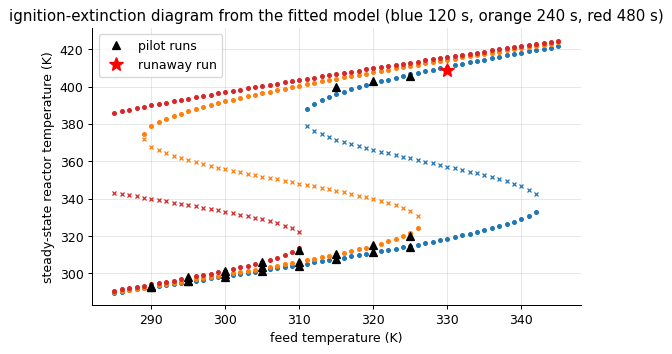

In [6]:
C_A0, cp_vol = 2500.0, 3.6e6
dH = -dTad_over * (1 + kappa_est) * cp_vol / C_A0
T0s = np.linspace(285, 345, 61)
fig, ax = plt.subplots()
for tau, col in ((120.0, "C0"), (240.0, "C1"), (480.0, "C3")):
    ie = energy.ignition_extinction(k0, Ea, dH, C_A0, tau, cp_vol, T0s, kappa_est, 295.0)
    for T0, Ts, sts in zip(ie["T0"], ie["T_ss"], ie["stable"]):
        for T_, st in zip(Ts, sts):
            ax.plot(T0, T_, "o" if st else "x", color=col, ms=3)
    band = T0s[np.array([len(Ts) for Ts in ie["T_ss"]]) == 3]
    print(f"tau = {tau:4.0f} s: multiplicity for T_feed in [{band.min():.0f}, {band.max():.0f}] K -> ignition on heating at about {band.max():.0f} K")
sub = q[q.note == "ok"]
ax.plot(sub.T_feed_K, sub.T_out_K, "k^", ms=6, label="pilot runs")
ax.plot(runaway.T_feed_K, runaway.T_out_K, "r*", ms=12, label="runaway run")
ax.set(xlabel="feed temperature (K)", ylabel="steady-state reactor temperature (K)", title="ignition-extinction diagram from the fitted model (blue 120 s, orange 240 s, red 480 s)"); ax.legend(); plt.show()

The fitted model reproduces the pilot plant: the runs sit on the extinguished branch except those at the
longest space time and highest feed temperatures, which ignited - and the trip at 330 K and 480 s is exactly
where the model says the low state ceases to exist. The operators did not do anything wrong; the reactor had
no cold steady state to go to.

## 6. Designing the production reactor

In [7]:
V_prod, v0 = 10.0, 10.0 / 3600                                        # m3, 10 m3/h feed -> tau = 3600 s
tau_prod = V_prod / v0
T0s_ = np.linspace(260, 340, 41)
rows = []
for kappa_new in (kappa_est, 1.5, 2.0, 3.0, 4.0):
    ss = energy.cstr_steady_states(k0, Ea, dH, C_A0, 300.0, tau_prod, cp_vol, kappa_new, 295.0, T_range=(250.0, 900.0))
    n = np.array([len(energy.cstr_steady_states(k0, Ea, dH, C_A0, T0, tau_prod, cp_vol, kappa_new, 295.0, T_range=(250.0, 900.0))["T"]) for T0 in T0s_])
    band = T0s_[n == 3]
    rows.append((round(kappa_new, 2), [round(t) for t in ss["T"]], [round(x, 3) for x in ss["X"]], f"{band.min():.0f}-{band.max():.0f} K" if band.size else "none"))
print("production reactor, tau = 1 h, T_feed = 300 K:")
print(pd.DataFrame(rows, columns=["jacket kappa", "steady-state T (K)", "X", "multiplicity for T_feed in"]).to_string(index=False))

production reactor, tau = 1 h, T_feed = 300 K:
 jacket kappa steady-state T (K)       X multiplicity for T_feed in
         0.79              [400] [0.996]                  260-270 K
         1.50              [369] [0.978]                  260-270 K
         2.00              [355] [0.948]                  260-272 K
         3.00              [333] [0.793]                       none
         4.00              [310] [0.373]                       none


At the production space time of an hour the pilot's jacket ratio leaves only the ignited state for any feed
warmer than 270 K: the reactor will light off on start-up, run at 400 K and 99.6 % conversion, and cannot be
extinguished by a cold feed - robust, but hot. More jacket capacity lowers the operating temperature, and
too much of it collapses the conversion (38 % at kappa = 4, where the reactor is cooled below its kinetics).
A jacket ratio of about 2 gives 95 % conversion at 355 K with a unique steady state for every feed
temperature above about 272 K: the design point, with 45 K of margin below the pilot's operating temperature
and no fold to fall off.

## 7. The report

In [8]:
kappa_design = 2.0
ss_op = energy.cstr_steady_states(k0, Ea, dH, C_A0, 300.0, tau_prod, cp_vol, kappa_design, 295.0, T_range=(250.0, 900.0))
report = f'''# Production reactor for A -> B: design basis

Kinetics (3 isothermal batch runs, nonlinear regression): first order; Ea = {Ea/1e3:.1f} +/- {arr['se_Ea']/1e3:.1f} kJ/mol, k0 = {k0:.2e} 1/s.
Pilot data: {len(p)} runs; {'; '.join(log)}. Kinetics reproduce the pilot conversions at the measured outlet temperatures.
Energy balance (regression on {len(low)} low-conversion pilot runs): adiabatic rise {dTad_over*(1+kappa_est):.0f} K (Delta H = {dH/1e3:.0f} kJ/mol), jacket kappa = {kappa_est:.2f}.
The pilot trip (run {int(runaway.run.iloc[0])}, T_feed 330 K, tau 480 s) is the loss of the extinguished steady state predicted by the model.

Design: V = 10 m3, feed 10 m3/h (tau = 1 h), T_feed = 300 K, jacket sized for kappa = UA/(v0 rho cp) = {kappa_design}: unique steady state at {ss_op['T'][-1]:.0f} K, X = {ss_op['X'][-1]:.3f}, for every feed temperature above 272 K.
Safety: with the pilot's jacket ratio ({kappa_est:.2f}) the reactor would run at 400 K; with kappa = 4 conversion collapses. The design point sits between, with no fold within the operating range. High-temperature trip at {ss_op['T'][-1]+30:.0f} K; the coolant-failure case (adiabatic time to maximum rate, notebook 09) is to be run before commissioning.
'''
print(report)

# Production reactor for A -> B: design basis

Kinetics (3 isothermal batch runs, nonlinear regression): first order; Ea = 69.4 +/- 0.3 kJ/mol, k0 = 8.40e+07 1/s.
Pilot data: 25 runs; run 6: conversion was entered in percent, divided by 100; run 13: outlet temperature was in degC, converted to K; run 25 (runaway) set aside for the safety analysis. Kinetics reproduce the pilot conversions at the measured outlet temperatures.
Energy balance (regression on 21 low-conversion pilot runs): adiabatic rise 184 K (Delta H = -265 kJ/mol), jacket kappa = 0.79.
The pilot trip (run 25, T_feed 330 K, tau 480 s) is the loss of the extinguished steady state predicted by the model.

Design: V = 10 m3, feed 10 m3/h (tau = 1 h), T_feed = 300 K, jacket sized for kappa = UA/(v0 rho cp) = 2.0: unique steady state at 355 K, X = 0.948, for every feed temperature above 272 K.
Safety: with the pilot's jacket ratio (0.79) the reactor would run at 400 K; with kappa = 4 conversion collapses. The design point sits 

Every number in the report traces to a file and a method, the pilot trip is explained rather than blamed,
and the safety recommendation is quantitative: the jacket ratio that removes the multiplicity, a trip
setting and the failure case still to be run. A design that cannot explain the pilot plant should not be
built; one that can, and states its window, is engineering.

## Inside the algorithm: the CSTR energy balance as a regression

In [9]:
x = low.X.to_numpy(); Tf = low.T_feed_K.to_numpy(); To = low.T_out_K.to_numpy()
A_ = np.vstack([np.ones_like(x), x, Tf]).T
c_hand = np.linalg.solve(A_.T @ A_, A_.T @ To)
print("by hand:", np.round(c_hand, 3), "; notebook:", np.round(coef, 3))

by hand: [130.449 102.587   0.557] ; notebook: [130.449 102.587   0.557]


## Exercises
1. Run the coolant-failure scenario (notebook 09) for the production reactor operating on the ignited branch: how far does the temperature rise, and how fast? Then for the kappa = 3 design. Which needs a relief system?
2. The batch kinetics have 1.5 % noise. Bootstrap the Arrhenius fit (resample residuals, refit 200 times) to get a distribution of Ea, and propagate it to the ignition temperature at tau = 480 s. How uncertain is the safe window?
3. **Implement it yourself:** write `clean_pilot_runs(df)` that applies the two unit repairs by rule (X > 1.05 -> percent; T < 200 -> degC) and returns the cleaned table with a log; verify it reproduces the notebook's table.